# 基于python的统计推断

In [1]:
import numpy as np

x, m = [], []
n = 10
for i in range(10000):
    d = np.random.normal(size=n)
    x.append(np.mean(d))
    m.append(np.median(d))
    
print("样本均值的方差：%.4f\n样本中位数的方差：%.4f" % \
      (np.var(x, ddof=1),np.var(m, ddof=1)))

样本均值的方差：0.0992
样本中位数的方差：0.1392


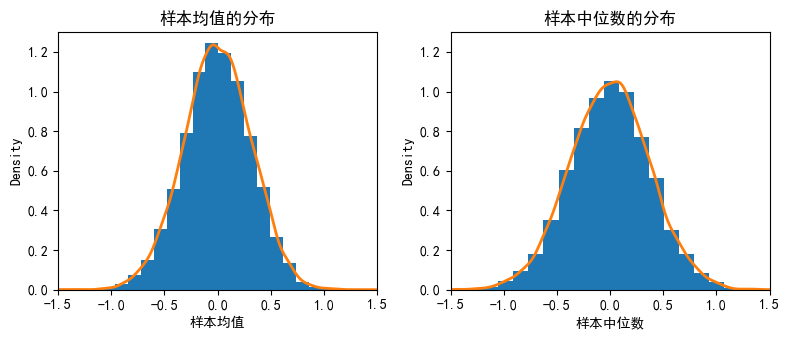

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus']=False

def plot_dis(df, ax, xlabel):
    df.plot(bins=20, kind='hist', density=True, ax=ax, legend=False)
    df.plot(kind='density', linewidth=2, ax=ax, legend=False)
    ax.set_ylim(0, 1.3)
    ax.set_xlim(-1.5, 1.5)
    ax.set_xlabel(xlabel)
    ax.set_title(xlabel + '的分布')

plt.subplots(1, 2, figsize=(8, 3.5))
ax1 = plt.subplot(121)
plot_dis(pd.DataFrame(x), ax1, '样本均值')
ax2 = plt.subplot(122)
plot_dis(pd.DataFrame(m), ax2, '样本中位数')

plt.tight_layout()
plt.show()

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
df=pd.read_csv('shu7.csv')
df.head()

,性别,家庭所在地,月生活费支出
0,女,中小城市,2535
1,男,大型城市,3520
2,男,大型城市,3042
3,女,中小城市,2704
4,女,中小城市,3380


In [5]:
df["月生活费支出"].mean()


3061.9666666666667

In [11]:
import scipy.stats as st
conf_level = 0.95 
x=df["月生活费支出"]
int=st.t.interval(conf_level,len(x)-1,loc=np.mean(x),scale=st.sem(x))

np.round(int,4)    

array([2920.3819, 3203.5514])

In [13]:
conf_level = 0.95 
int=st.t.interval(conf_level,len(x)-1,loc=np.mean(x),scale=st.sem(x))
np.round(int,4)  

array([2920.3819, 3203.5514])

In [15]:
pip install researchpy

In [17]:
import researchpy as rp
df["月生活费支出"]=df["月生活费支出"].astype('int64') 
rp.summary_cont(df["月生活费支出"])

C:\Users\lvp\anaconda3\Lib\site-packages\researchpy\summary.py:38: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '月生活费支出' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  table.iloc[0,0] = group1.name


,Variable,N,Mean,SD,SE,95% Conf.,Interval
0,月生活费支出,60.0,3061.9667,548.0827,70.7572,2920.3819,3203.5514


In [19]:
# 一个总体均值的检验
from statsmodels.stats.weightstats import ztest 
z,p_value=ztest(x1=df["月生活费支出"],value=1500,alternative="larger")  
z,p_value

(22.07503086628771, 2.7463391861566237e-108)

In [21]:
# 一个总体均值的检验
from statsmodels.stats.weightstats import ztest 
z,p_value=ztest(x1=df["月生活费支出"],value=1500,alternative="smaller")  
z,p_value

(22.07503086628771, 1.0)

In [23]:
# 一个总体均值的检验
from statsmodels.stats.weightstats import ztest 
z,p_value=ztest(x1=df["月生活费支出"],value=1500,alternative="two-sided")  
z,p_value

(22.07503086628771, 5.492678372313247e-108)

In [25]:
from scipy.stats import ttest_1samp 
t,p_value=ttest_1samp(a=df["月生活费支出"],popmean=1500)    #  popmean为假设的总体均值
t,p_value

(22.07503086628771, 3.344899777412843e-30)

In [27]:
# 两个总体均值之差的检验（独立大样本）
from statsmodels.stats.weightstats import ztest

x1 =df["月生活费支出"][df["性别"]=="女"]
x2 =df["月生活费支出"][df["性别"]=="男"]


z, p_value = ztest(x1=x1, x2=x2, alternative='two-sided')
print(f"月生活费支出女{x1.mean(): .4f}，月生活费支出男{x2.mean(): .4f}\
      \nz统计量值 ={z: .4f}，p值 ={p_value: .4f}")

月生活费支出女 3197.2000，月生活费支出男 2872.6400      
z统计量值 = 2.3461，p值 = 0.0190


In [29]:
# 一个总体方差的检验
import pandas as pd
from scipy.stats import chi2
x = df['月生活费支出']
sigma0_2 = 90
s2 = x.var(); n = len(x); df=n-1
chi2_value = (n-1) * s2 / sigma0_2
p_value = 1 - chi2.cdf(chi2_value, df=df)
print(f"月生活费支出的方差 = {s2 :.4f}，卡方统计量值 ={chi2_value: .4f}，\
  自由度df = {df}，p值 ={p_value: .4f}")


月生活费支出的方差 = 300394.6090，卡方统计量值 = 196925.3548，  自由度df = 59，p值 = 0.0000


In [31]:
# 两个总体方差比的检验
import pandas as pd
from scipy.stats import f
import numpy as np
df=pd.read_csv('shu7.csv')
x1 =df["月生活费支出"][df["性别"]=="女"]
x2 =df["月生活费支出"][df["性别"]=="男"]

s1_square = x1.var(); dfn = len(x1)-1
s2_square = x2.var(); dfd = len(x2)-1

f_value = s1_square / s2_square
p_value = (1-(f.cdf(f_value, dfn=dfn, dfd=dfd))) * 2
print(f"F统计量值 ={f_value: .4f}，p值 ={p_value: .4f}")



F统计量值 = 1.3570，p值 = 0.4399


正态检验

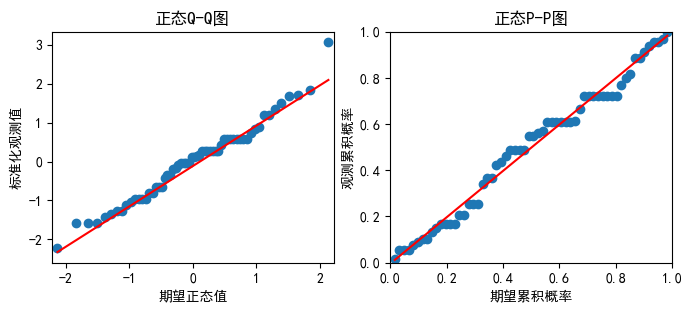

In [33]:
# 绘制正态概率图
import pandas as pd
import statsmodels.api as sm
from matplotlib import pyplot as plt
plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus']=False
pplot = sm.ProbPlot(df["月生活费支出"], fit=True)
plt.subplots(1, 2, figsize=(8, 3))

# 绘制正态Q-Q图
ax1 = plt.subplot(121)
pplot.qqplot(line='q', ax=ax1, xlabel='期望正态值', ylabel='标准化观测值')
ax1.set_title('正态Q-Q图', fontsize=12)

# 绘制正态P-P图
ax2 = plt.subplot(122)
pplot.ppplot(line='r', ax=ax2, xlabel='期望累积概率', ylabel='观测累积概率')
ax2.set_title('正态P-P图', fontsize=12)
plt.show()



In [35]:
# Shapiro-Wilk 正态性检验
import pandas as pd
from scipy.stats import shapiro
W, p_value = shapiro(df["月生活费支出"])
print(f"统计量W ={W: .4f}，p值 ={p_value: .4g}")


统计量W = 0.9795，p值 = 0.4057


In [37]:
# K-S 正态性检验
import pandas as pd
from scipy.stats import kstest

x=df["月生活费支出"]
D, p_value = kstest(x, 'norm', alternative='two-sided', mode='asymp',
       args=(x.mean(),x.std()))
print(f"统计量D ={D: .4f}，p值 ={p_value: .4g}")


统计量D = 0.0975，p值 = 0.6179


#方差分析

In [39]:
# 拟合单因子方差分析模型并输出方差分析表
from statsmodels.formula.api import ols
from statsmodels.stats.anova import anova_lm
model1 = ols(formula='月生活费支出~家庭所在地',data=df).fit() # 拟合方差分析模型
anova_lm(model1,typ=1)

,df,sum_sq,mean_sq,F,PR(>F)
家庭所在地,2.0,2.637416e+05,131870.814423,0.430517,0.652269
Residual,57.0,1.745954e+07,306307.724640,NaN,NaN


In [67]:
# 使用summary函数输出模型摘要
model1.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                 月生活费支出   R-squared:                       0.015
Model:                            OLS   Adj. R-squared:                 -0.020
Method:                 Least Squares   F-statistic:                    0.4305
Date:                Thu, 15 May 2025   Prob (F-statistic):              0.652
Time:                        14:41:44   Log-Likelihood:                -462.57
No. Observations:                  60   AIC:                             931.1
Df Residuals:                      57   BIC:                             937.4
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
=================================================================================
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
Intercept      3035.2083    112.973     26.867      0.000    2808.984    3261.432
家庭所在地[T.乡镇地区]   -85.7083    208.311     -0.411      0.682    -502.845     331.428
家庭所在地[T.大型城市]    94.7147    156.665      0.605      0.548    -219.001     408.431
==============================================================================
Omnibus:                        0.913   Durbin-Watson:                   1.396
Prob(Omnibus):                  0.634   Jarque-Bera (JB):                0.460
Skew:                           0.198   Prob(JB):                        0.795
Kurtosis:                       3.164   Cond. No.                         3.73
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

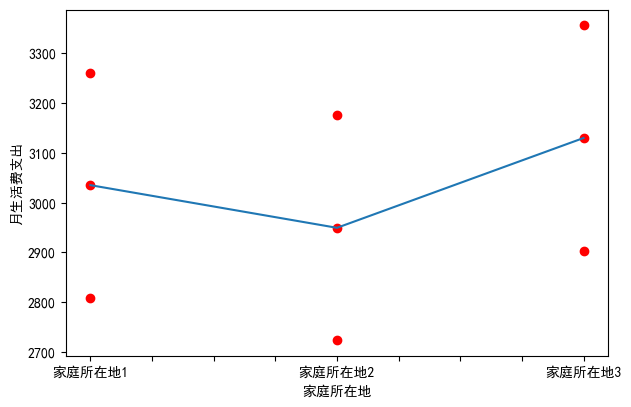

In [41]:
# # 绘制样本的均值图
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus']=False
model1 = ols(formula='月生活费支出~家庭所在地',data=df).fit()
mean = model1.params.values[0]
lci, uci = model1.conf_int().iloc[0].values
df_mean = pd.DataFrame([lci, mean, uci], index=['lci', 'mean', 'uci'],
                       columns=['家庭所在地1'])
df_mean['家庭所在地2'] = df_mean['家庭所在地1'] + model1.params.values[1]
df_mean['家庭所在地3'] = df_mean['家庭所在地1'] + model1.params.values[2]

ax = df_mean.T.plot(ls='', marker='o',legend=False, c='red', 
                    figsize=(7, 4.5), xlabel='家庭所在地', ylabel='月生活费支出')
ax = df_mean.loc['mean'].plot()
# fig = ax.get_figure()
# fig.savefig('./图.jpg')

In [43]:
# 多重比较的HSD方法
import pandas as pd
from statsmodels.stats.multicomp import MultiComparison

mc = MultiComparison(df['月生活费支出'], groups=df['家庭所在地'])
print(mc.tukeyhsd(alpha=0.05))

  Multiple Comparison of Means - Tukey HSD, FWER=0.05  
group1 group2 meandiff p-adj    lower    upper   reject
-------------------------------------------------------
  中小城市   乡镇地区 -85.7083 0.9111 -586.9924 415.5757  False
  中小城市   大型城市  94.7147 0.8182 -282.2865  471.716  False
  乡镇地区   大型城市 180.4231 0.6575 -315.1579 676.0041  False
-------------------------------------------------------


In [45]:
# 双因子方差分析表
import pandas as pd
from statsmodels.formula.api import ols
from statsmodels.stats.anova import anova_lm
model2m = ols(formula='月生活费支出~家庭所在地+性别',data=df).fit()   # 拟合主效应模型
anova_lm(model2m, typ=1)  # 输出方差分析表


,df,sum_sq,mean_sq,F,PR(>F)
家庭所在地,2.0,2.637416e+05,1.318708e+05,0.477564,0.622795
性别,1.0,1.996138e+06,1.996138e+06,7.228922,0.009432
Residual,56.0,1.546340e+07,2.761322e+05,NaN,NaN


In [75]:
# 输出模型的其他信息
# print(model2m.summary())
model2m.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                 月生活费支出   R-squared:                       0.128
Model:                            OLS   Adj. R-squared:                  0.081
Method:                 Least Squares   F-statistic:                     2.728
Date:                Thu, 15 May 2025   Prob (F-statistic):             0.0525
Time:                        14:41:50   Log-Likelihood:                -458.93
No. Observations:                  60   AIC:                             925.9
Df Residuals:                      56   BIC:                             934.2
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
=================================================================================
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
Intercept      3132.2572    113.174     27.676      0.000    2905.542    3358.972
家庭所在地[T.乡镇地区]   -27.4790    198.967     -0.138      0.891    -426.057     371.099
家庭所在地[T.大型城市]   221.6248    156.058      1.420      0.161     -90.996     534.246
性别[T.男]        -388.1954    144.382     -2.689      0.009    -677.428     -98.963
==============================================================================
Omnibus:                        0.226   Durbin-Watson:                   1.548
Prob(Omnibus):                  0.893   Jarque-Bera (JB):                0.418
Skew:                           0.067   Prob(JB):                        0.811
Kurtosis:                       2.614   Cond. No.                         4.10
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [47]:
# 交互效应方差分析表
import pandas as pd
from statsmodels.formula.api import ols
from statsmodels.stats.anova import anova_lm

model2i = ols(formula='月生活费支出~家庭所在地+性别+家庭所在地:性别',data=df).fit()
anova_lm(model2i, typ=1)


,df,sum_sq,mean_sq,F,PR(>F)
家庭所在地,2.0,2.637416e+05,1.318708e+05,0.468405,0.628520
性别,1.0,1.996138e+06,1.996138e+06,7.090278,0.010191
家庭所在地:性别,2.0,2.606889e+05,1.303445e+05,0.462983,0.631878
Residual,54.0,1.520271e+07,2.815317e+05,NaN,NaN


In [79]:
# 输出模型的其他信息
# print(model2m.summary())
model2m.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                 月生活费支出   R-squared:                       0.128
Model:                            OLS   Adj. R-squared:                  0.081
Method:                 Least Squares   F-statistic:                     2.728
Date:                Thu, 15 May 2025   Prob (F-statistic):             0.0525
Time:                        14:41:53   Log-Likelihood:                -458.93
No. Observations:                  60   AIC:                             925.9
Df Residuals:                      56   BIC:                             934.2
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
=================================================================================
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
Intercept      3132.2572    113.174     27.676      0.000    2905.542    3358.972
家庭所在地[T.乡镇地区]   -27.4790    198.967     -0.138      0.891    -426.057     371.099
家庭所在地[T.大型城市]   221.6248    156.058      1.420      0.161     -90.996     534.246
性别[T.男]        -388.1954    144.382     -2.689      0.009    -677.428     -98.963
==============================================================================
Omnibus:                        0.226   Durbin-Watson:                   1.548
Prob(Omnibus):                  0.893   Jarque-Bera (JB):                0.418
Skew:                           0.067   Prob(JB):                        0.811
Kurtosis:                       2.614   Cond. No.                         4.10
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

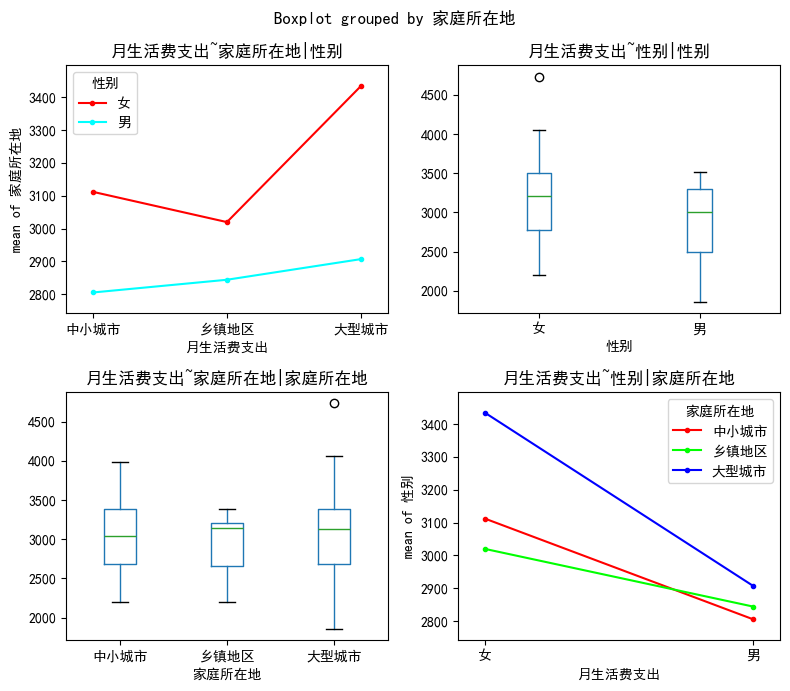

In [49]:
# 绘制主效应和交互效应图
import pandas as pd
from statsmodels.graphics.api import interaction_plot
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus']=False


y_col = '月生活费支出'; x1_col = '性别'; x2_col = '家庭所在地'

plt.subplots(2, 2, figsize=(8, 7))
ax1 = plt.subplot(221)
interaction_plot(x=df[x2_col],trace=df[x1_col], response=df[y_col],
                 xlabel=y_col, ylabel=x2_col, ax=ax1)
ax1.set_title(f'{y_col}~{x2_col}|{x1_col}')

ax2 = plt.subplot(222)
df.boxplot(column=y_col, by=x1_col,grid=False, ax=ax2)
ax2.set_title(f'{y_col}~{x1_col}|{x1_col}')

ax3 = plt.subplot(223)
df.boxplot(column=y_col, by=x2_col,grid=False, ax=ax3)
ax3.set_title(f'{y_col}~{x2_col}|{x2_col}')

ax4 = plt.subplot(224)
interaction_plot(x=df[x1_col],trace=df[x2_col], response=df[y_col],
                 xlabel=y_col, ylabel=x1_col, ax=ax4)
ax4.set_title(f'{y_col}~{x1_col}|{x2_col}')

plt.tight_layout()

In [51]:
# 不同品种产量的Levene检验
from scipy.stats import levene
sample1 = df.loc[df['家庭所在地']=='大型城市', '月生活费支出'].values
sample2 = df.loc[df['家庭所在地']=='中小城市', '月生活费支出'].values
sample3 = df.loc[df['家庭所在地']=='乡镇地区', '月生活费支出'].values

F, p_value = levene(sample1, sample2, sample3)
print(f"统计量F ={F: .4f}，p值 ={p_value: .4g}")

统计量F = 0.8556，p值 = 0.4304


#############分类数据的假设检验

In [53]:
#一维频数表
# 使用value.counts()函数生成专业的简单频数表
import pandas as pd
df1 = pd.read_csv("shu3.csv") 
df1.info()
df1.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   姓名      50 non-null     object
 1   性别      50 non-null     object
 2   专业      50 non-null     object
 3   满意度     50 non-null     object
 4   考试分数    50 non-null     int64 
dtypes: int64(1), object(4)
memory usage: 2.1+ KB


,姓名,性别,专业,满意度,考试分数
0,张青松,男,会计学,不满意,82
1,王宇翔,男,金融学,一般,81
2,田思雨,女,会计学,满意,75
3,徐丽娜,女,管理学,一般,86
4,张志杰,男,会计学,不满意,77


In [55]:
tab1=df1['满意度'].value_counts()     # 生成频数表（类型是序列）
df2=pd.DataFrame(tab1) 
df2

,count
满意度,
满意,23
一般,15
不满意,12


In [57]:
# 期望频数相等时的拟合优度检验
import pandas as pd
from scipy.stats import chisquare

chi2, p_value = chisquare(f_obs=df2['count'])
print(f"卡方统计量 ={chi2: .2f}，p值 ={p_value: .4g}")

# 注：cihsquare函数默认f_exp=None，即默认期望频数相等。

卡方统计量 = 3.88，p值 = 0.1437


In [59]:
#两个分类变量的独立性检验
from scipy.stats import chi2_contingency
df1 = pd.read_csv("shu3.csv") 
count = pd.crosstab(index=df1['性别'], columns=df1['满意度'])   # 生成列联表
chi2, p_value, df, f_exp=chi2_contingency(count)  # 检验列联表
print(f"卡方统计量 ={chi2: .3f}，p值 ={p_value: .4g}\n期望频数为：\n{f_exp}")


卡方统计量 = 5.145，p值 = 0.07633
期望频数为：
[[ 6.6   5.28 10.12]
 [ 8.4   6.72 12.88]]


In [94]:
df1.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   姓名      50 non-null     object
 1   性别      50 non-null     object
 2   专业      50 non-null     object
 3   满意度     50 non-null     object
 4   考试分数    50 non-null     int64 
dtypes: int64(1), object(4)
memory usage: 2.1+ KB


In [61]:
# 计算两个类别变量的相关性度量统计量
import math

n=50
chi2= 5.145   # 卡方值
phi=math.sqrt(chi2/n)
v=math.sqrt(chi2/n*(2-1))
c=math.sqrt(chi2/(chi2+n))
print(f'phi系数 ={phi: .6f}\nv系数 ={v: .6f}\nc系数 ={c: .6f}')


phi系数 = 0.320780
v系数 = 0.320780
c系数 = 0.305450


######相关系数的检验

In [63]:
# 计算相关系数矩阵
import pandas as pd
from scipy.stats import pearsonr
df = pd.read_csv("shu8.csv")
df.info()
df


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25 entries, 0 to 24
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   样本编号    25 non-null     int64  
 1   每股收益    25 non-null     float64
 2   每股净资产   25 non-null     float64
 3   每股现金流量  25 non-null     float64
 4   总股本     25 non-null     float64
dtypes: float64(4), int64(1)
memory usage: 1.1 KB


,样本编号,每股收益,每股净资产,每股现金流量,总股本
0,1,0.88,5.86,1.50,2.28
1,2,1.14,11.13,4.95,9.09
2,3,4.88,17.30,1.93,7.37
3,4,3.23,8.08,1.80,1.45
4,5,7.83,19.97,4.13,6.32
5,6,2.76,1.62,0.55,0.22
6,7,1.64,10.74,2.68,2.02
7,8,9.54,18.54,6.78,4.38
8,9,2.67,7.28,2.28,6.43
9,10,1.10,9.61,0.43,5.59


In [65]:
corr = df.iloc[:,1:].corr()
corr

,每股收益,每股净资产,每股现金流量,总股本
每股收益,1.000000,0.886292,0.598971,0.254539
每股净资产,0.886292,1.000000,0.482134,0.521195
每股现金流量,0.598971,0.482134,1.000000,0.147115
总股本,0.254539,0.521195,0.147115,1.000000


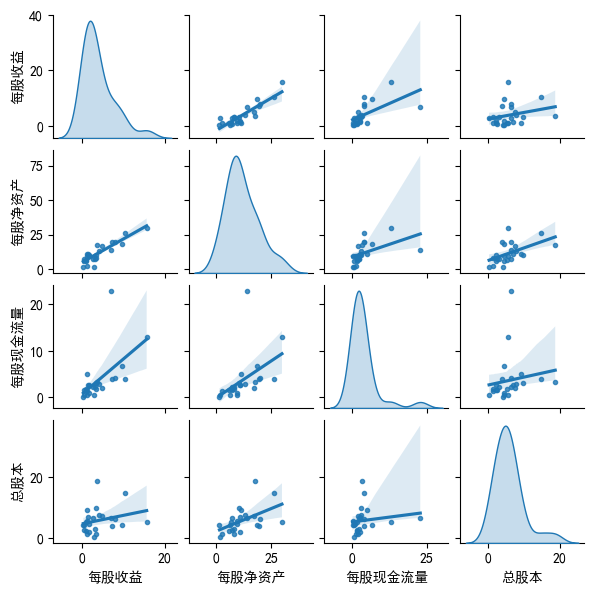

In [103]:
# 绘制散点图矩阵
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns #可以绘制95%置信区间图
plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False
sns.pairplot(df[['每股收益','每股净资产','每股现金流量','总股本']],
             height=1.5,diag_kind='kde', markers='.',kind='reg' )

<Axes: >

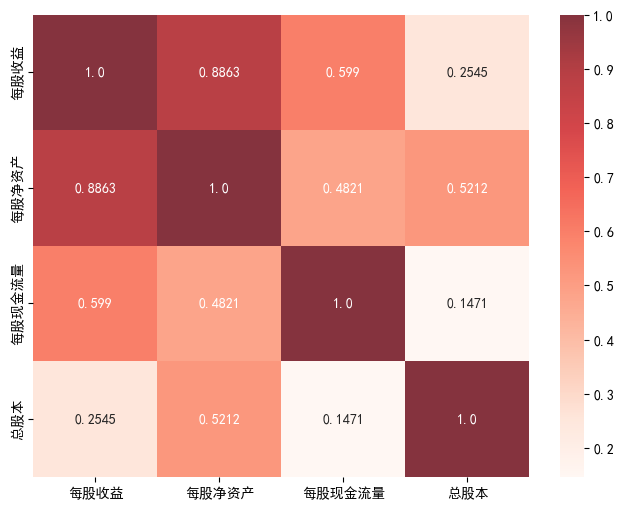

In [67]:
### 绘制 散点图矩阵制代码

plt.rcParams['font.sans-serif'] = ['SimHei']  # 显示中文
plt.rcParams['axes.unicode_minus'] = False    # 显示负号

plt.figure(figsize=(8, 6))     # 设置图形大小
corr=df[['每股收益', '每股净资产', '每股现金流量', '总股本']].corr()     # 计算相关系数矩阵 
sns.heatmap(corr,cmap='Reds',alpha=0.8, annot=True,fmt='.4')
                                   # 使用调色板'Reds',显示值，保留4位小数

In [69]:
# 相关系数的检验
import pandas as pd
from scipy.stats import pearsonr
col = ['每股收益', '每股净资产', '每股现金流量', '总股本']
df_pvalue = pd.DataFrame(index=col, columns=col)
for i in range(1, 5):
    for j in range(1, 5):
        cor, p_value = pearsonr(df.iloc[:,i], df.iloc[:,j]) # 计算Pearson相关系数
        df_pvalue.iloc[i-1, j-1] = p_value    # 给出双尾具有P值

df_pvalue

,每股收益,每股净资产,每股现金流量,总股本
每股收益,0.0,0.0,0.001558,0.21949
每股净资产,0.0,0.0,0.01466,0.007548
每股现金流量,0.001558,0.01466,0.0,0.482835
总股本,0.21949,0.007548,0.482835,0.0


一元线性回归

In [71]:
df[['每股收益', '每股净资产', '每股现金流量', '总股本']].describe()

,每股收益,每股净资产,每股现金流量,总股本
count,25.000000,25.000000,25.000000,25.000000
mean,3.821200,11.746800,3.617200,5.738800
std,3.805354,7.214773,4.769698,4.119208
min,0.230000,1.480000,0.150000,0.220000
25%,1.100000,7.280000,1.480000,2.990000
50%,2.760000,10.220000,2.280000,5.190000
75%,4.880000,17.300000,3.900000,6.790000
max,15.650000,29.820000,22.800000,18.710000


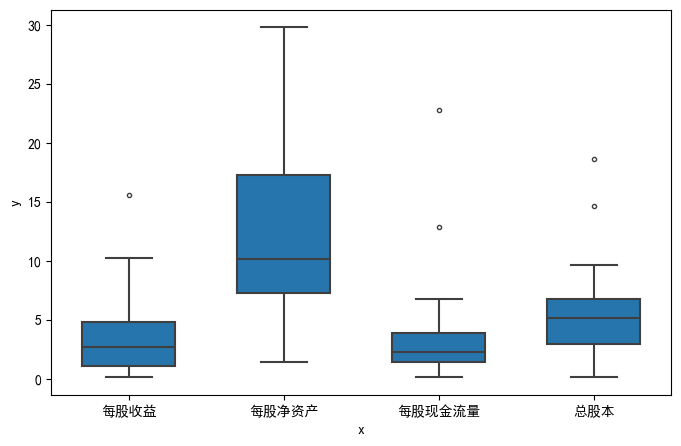

In [109]:
### 绘制箱形图
plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False

df1= pd.melt(df, value_vars=["每股收益","每股净资产","每股现金流量","总股本"], 
             var_name='x', value_name='y')  # 融合数据
plt.figure(figsize=(8, 5))
sns.boxplot(data=df1,x='x',y='y',
            width=0.6,linewidth=1.5,    # 设置箱子的宽度和线宽
            saturation=0.9,  # 设置颜色的原始饱和度比例。1表示完全饱和
            fliersize=3,     # 设置离群点标记的大小
            notch=False,     # 设置notch可绘制出箱子的凹槽
            #palette="Set2",  # 设置调色板
            orient="v")      # 如果变量是在行的位置，可设置orient="h",绘制水平箱线图

plt.show()

In [73]:

import researchpy as rp
rp.summary_cont(df[["每股收益","每股净资产","每股现金流量","总股本"]])

C:\Users\lvp\anaconda3\Lib\site-packages\researchpy\summary.py:102: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '每股收益' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  table_a.iloc[0,0] = ix
C:\Users\lvp\anaconda3\Lib\site-packages\researchpy\summary.py:102: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '每股净资产' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  table_a.iloc[0,0] = ix
C:\Users\lvp\anaconda3\Lib\site-packages\researchpy\summary.py:102: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '每股现金流量' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  table_a.iloc[0,0] = ix
C:\Users\lvp\anaconda3\Lib\site-packages\resea

,Variable,N,Mean,SD,SE,95% Conf.,Interval
0,每股收益,25.0,3.8212,3.8054,0.7611,2.2504,5.3920
1,每股净资产,25.0,11.7468,7.2148,1.4430,8.7687,14.7249
2,每股现金流量,25.0,3.6172,4.7697,0.9539,1.6484,5.5860
3,总股本,25.0,5.7388,4.1192,0.8238,4.0385,7.4391


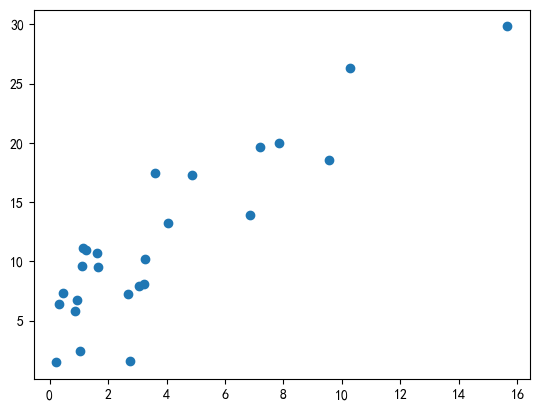

In [75]:
#绘图每股收益和每股净资产的点图
plt.rcParams['font.sans-serif'] = ['SimHei']
import matplotlib.pyplot as plt
x = df['每股收益']
y = df['每股净资产']
plt.scatter(x,y)
plt.show()

In [77]:
# 拟合一元回归模型
import pandas as pd
from statsmodels.formula.api import ols

model1 = ols("每股收益~每股净资产",data=df).fit()
#print(model1.summary())
model1.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                   每股收益   R-squared:                       0.786
Model:                            OLS   Adj. R-squared:                  0.776
Method:                 Least Squares   F-statistic:                     84.23
Date:                Thu, 07 May 2026   Prob (F-statistic):           3.76e-09
Time:                        17:18:49   Log-Likelihood:                -49.130
No. Observations:                  25   AIC:                             102.3
Df Residuals:                      23   BIC:                             104.7
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -1.6700      0.698     -2.392      0.025      -3.115      -0.225
每股净资产          0.4675      0.051      9.178      0.000       0.362       0.573
==============================================================================
Omnibus:                        1.134   Durbin-Watson:                   1.993
Prob(Omnibus):                  0.567   Jarque-Bera (JB):                1.082
Skew:                           0.419   Prob(JB):                        0.582
Kurtosis:                       2.420   Cond. No.                         26.7
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [79]:
# 输出方差分析表
from statsmodels.stats.anova import anova_lm
anova_lm(model1, typ=1)

,df,sum_sq,mean_sq,F,PR(>F)
每股净资产,1.0,272.995423,272.995423,84.233159,3.760409e-09
Residual,23.0,74.541841,3.240950,NaN,NaN


In [81]:
# 计算x0=10时每股收益的点预测值
model1.predict(exog=dict(每股净资产=10))


0    3.004632
dtype: float64

模型检验

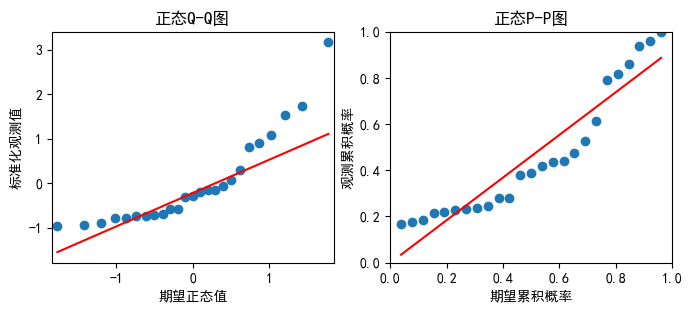

In [83]:
# 绘制正态概率图
import statsmodels.api as sm
from matplotlib import pyplot as plt
plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus']=False
pplot = sm.ProbPlot(df["每股收益"], fit=True)
plt.subplots(1, 2, figsize=(8, 3))
ax1 = plt.subplot(121)
pplot.qqplot(line='q', ax=ax1, xlabel='期望正态值', ylabel='标准化观测值')
ax1.set_title('正态Q-Q图', fontsize=12)
ax2 = plt.subplot(122)
pplot.ppplot(line='r', ax=ax2, xlabel='期望累积概率', ylabel='观测累积概率')
ax2.set_title('正态P-P图', fontsize=12)
plt.show()

In [85]:
# Shapiro-Wilk 正态性检验
import pandas as pd
from scipy.stats import shapiro
W, p_value = shapiro(df["每股收益"])
print(f"统计量W ={W: .4f}，p值 ={p_value: .4g}")

统计量W = 0.8221，p值 = 0.0005443


In [131]:
# 输出残差和标准化残差
import pandas as pd
import numpy as np
from statsmodels.formula.api import ols

model1 = ols("每股收益~每股净资产",data=df).fit()
df1=pd.DataFrame({"样本编号": df['样本编号'],"每股收益": df['每股收益'],
                 "点预测值":model1.fittedvalues,"残差": model1.resid, 
                 "标准化残差": np.array(model1.resid_pearson)})

round(df1,4).head()  

,样本编号,每股收益,点预测值,残差,标准化残差
0,1,0.88,1.0693,-0.1893,-0.1052
1,2,1.14,3.5329,-2.3929,-1.3292
2,3,4.88,6.4171,-1.5371,-0.8538
3,4,3.23,2.1071,1.1229,0.6237
4,5,7.83,7.6653,0.1647,0.0915


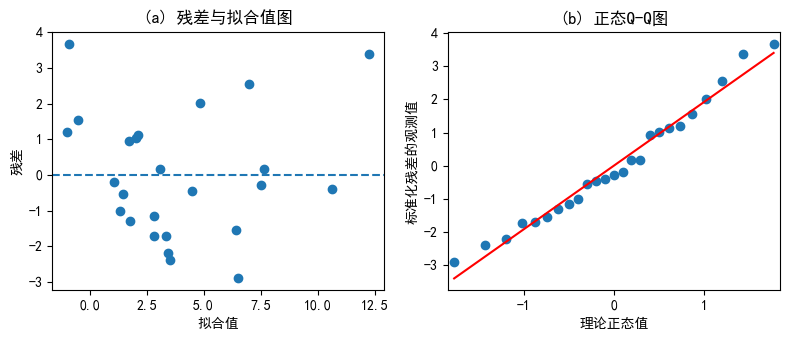

In [87]:
# 绘制模型的诊断图
import pandas as pd
import numpy as np
from statsmodels.formula.api import ols
import statsmodels.api as sm
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus']=False

model1 = ols("每股收益~每股净资产",data=df).fit()   # 拟合模型

# 图（a）残差与拟合值图
plt.subplots(1, 2, figsize=(8, 3.5))
plt.subplot(121)
plt.scatter(model1.fittedvalues, model1.resid)
plt.xlabel('拟合值')
plt.ylabel('残差')
plt.title('(a) 残差与拟合值图', fontsize=12)
plt.axhline(0, ls='--')

# 图（b）正态Q-Q图
ax2 = plt.subplot(122)
pplot = sm.ProbPlot(model1.resid, fit=True)
pplot.qqplot(line='r', ax=ax2, xlabel='理论正态值', ylabel='标准化残差的观测值')
ax2.set_title('(b) 正态Q-Q图', fontsize=12)

plt.tight_layout()
plt.show()


多元线性

In [89]:
# 拟合多元回归模型
from statsmodels.formula.api import ols
import pandas as pd
model_m = ols("每股收益~每股净资产+每股现金流量+总股本",data=df).fit()
#print(model_m.summary())
model_m.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                   每股收益   R-squared:                       0.871
Model:                            OLS   Adj. R-squared:                  0.853
Method:                 Least Squares   F-statistic:                     47.41
Date:                Thu, 07 May 2026   Prob (F-statistic):           1.58e-09
Time:                        17:19:17   Log-Likelihood:                -42.740
No. Observations:                  25   AIC:                             93.48
Df Residuals:                      21   BIC:                             98.35
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -1.1167      0.597     -1.870      0.076      -2.359       0.125
每股净资产          0.4903      0.055      8.891      0.000       0.376       0.605
每股现金流量         0.1505      0.072      2.091      0.049       0.001       0.300
总股本           -0.2381      0.086     -2.783      0.011      -0.416      -0.060
==============================================================================
Omnibus:                        0.628   Durbin-Watson:                   1.992
Prob(Omnibus):                  0.730   Jarque-Bera (JB):                0.697
Skew:                           0.213   Prob(JB):                        0.706
Kurtosis:                       2.301   Cond. No.                         32.1
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [91]:
# 输出方差分析表
from statsmodels.stats.anova import anova_lm
anova_lm(model_m, typ=1)

,df,sum_sq,mean_sq,F,PR(>F)
每股净资产,1.0,272.995423,272.995423,128.229092,2.105681e-10
每股现金流量,1.0,13.342307,13.342307,6.267035,2.062595e-02
总股本,1.0,16.491240,16.491240,7.746125,1.114149e-02
Residual,21.0,44.708294,2.128966,NaN,NaN


In [173]:
# 计算标准回归系数
import pandas as pd
from statsmodels.formula.api import ols
from scipy import stats         # scipy是基于numpy的科学计算包
df = pd.read_csv("shu8.csv")
df.drop(['样本编号'],axis=1,inplace=True)         # 删除样本编号一列
z = stats.zscore(df,ddof=1)                      # 数据框标准化
df1=pd.DataFrame(data=z)
#df1=pd.DataFrame(data=z,columns=['z每股收益','z每股净资产','z每股现金流量','z总股本'])  
df1 = df1.rename(columns={'每股收益':'z每股收益','每股净资产':'z每股净资产','每股现金流量':'z每股现金流量','总股本':'z总股本'})
model_z = ols("z每股收益~z每股净资产+z每股现金流量+z总股本",df1).fit()
model_z.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                  z每股收益   R-squared:                       0.871
Model:                            OLS   Adj. R-squared:                  0.853
Method:                 Least Squares   F-statistic:                     47.41
Date:                Thu, 15 May 2025   Prob (F-statistic):           1.58e-09
Time:                        14:55:37   Log-Likelihood:                -9.3293
No. Observations:                  25   AIC:                             26.66
Df Residuals:                      21   BIC:                             31.53
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept   1.874e-16      0.077   2.44e-15      1.000      -0.159       0.159
z每股净资产         0.9297      0.105      8.891      0.000       0.712       1.147
z每股现金流量        0.1887      0.090      2.091      0.049       0.001       0.376
z总股本          -0.2578      0.093     -2.783      0.011      -0.450      -0.065
==============================================================================
Omnibus:                        0.628   Durbin-Watson:                   1.992
Prob(Omnibus):                  0.730   Jarque-Bera (JB):                0.697
Skew:                           0.213   Prob(JB):                        0.706
Kurtosis:                       2.301   Cond. No.                         2.23
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [93]:
# 每股净资产=5、每股现金流量=5、总股本=5时每股收益的点预测值
model_m.predict(exog=dict(每股净资产=5,每股现金流量=5,总股本=5))

0    0.896996
dtype: float64

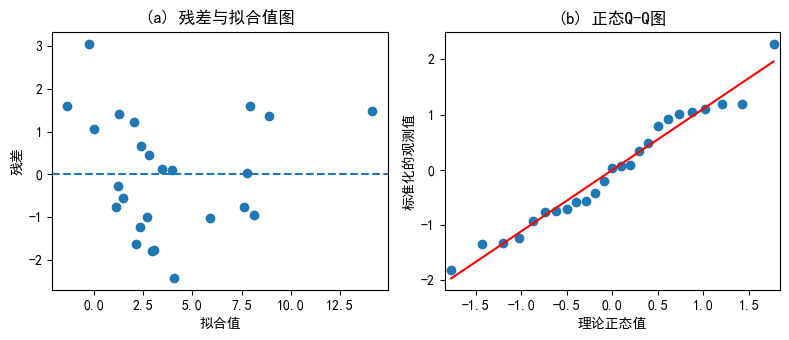

In [121]:
# 绘制残差图诊断模型
from statsmodels.formula.api import ols
import statsmodels.api as sm
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus']=False
df = pd.read_csv("shu8.csv")
model_m = ols("每股收益~每股净资产+每股现金流量+总股本",data=df).fit()
x = model_m.fittedvalues; y = model_m.resid
plt.subplots(1, 2, figsize=(8, 3.5))
plt.subplot(121)
plt.scatter(model_m.fittedvalues, model_m.resid)
plt.xlabel('拟合值')
plt.ylabel('残差')
plt.title('(a) 残差与拟合值图', fontsize=12)
plt.axhline(0, ls='--')

ax2 = plt.subplot(122)
pplot = sm.ProbPlot(model_m.resid, fit=True)
pplot.qqplot(line='r', ax=ax2, xlabel='理论正态值', ylabel='标准化的观测值')
ax2.set_title('(b) 正态Q-Q图', fontsize=12)

plt.tight_layout()
plt.show()


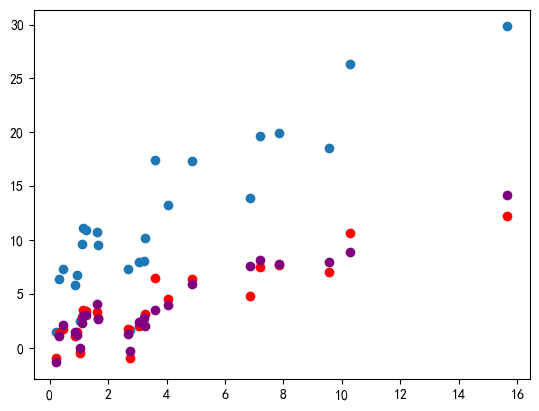

In [95]:
#绘图每股收益和每股净资产的点图
plt.rcParams['font.sans-serif'] = ['SimHei']
import matplotlib.pyplot as plt
x = df['每股收益']
y = df['每股净资产']
plt.scatter(x,y)
plt.scatter(x,model1.fittedvalues,c="red")
plt.scatter(x,model_m.fittedvalues,c="purple")
plt.show()